# Tutorial 3: Revising a Model

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TARPS-group/prob-pipe/blob/main/docs/tutorials/03_modifying_model.ipynb)

The model checks implemented in [Tutorial 2](02_model_checking.ipynb) indicated some potential inadequacies in
our modeling assumptions. In this tutorial, we modify our model in an attempt to address these complexities.

Building on the previous tutorials, this notebook will provide further practice constructing probabilistic
models with the merge operator. It will also demonstrate how components can easily be swapped in or out
in a modular fashion.

In [1]:
# @title Setup: install ProbPipe on Colab (run this first)
# On Google Colab, install ProbPipe with PyMC and nutpie, and download the data; elsewhere this cell does nothing.
try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import os
    import urllib.request

    %pip install --quiet 'probpipe-core[pymc,nutpie] @ git+https://github.com/TARPS-group/prob-pipe.git@main'
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/TARPS-group/prob-pipe/main/'
        'docs/tutorials/data/moose.csv',
        'data/moose.csv',
    )

In [ ]:
import warnings

import jax
import jax.numpy as jnp
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt

from probpipe import (
    Beta,
    HalfNormal,
    LogNormal,
    Normal,
    Poisson,
    condition_on,
    conditional_distribution,
    summarize,
    predictive_check,
    workflow_run,
)

# TensorFlow Probability warns that JAX runs in 32-bit precision, which these models use.
warnings.filterwarnings('ignore', message=r'Explicitly requested dtype float64')

# Cleaner printing for floats
np.set_printoptions(precision=3, suppress=True)

# set random seed for reproducibility
workflow_run.set_default(seed=532431)

In [3]:
# load data as before
data = pd.read_csv('data/moose.csv')
years = data['year'].to_numpy()
observed_counts = jnp.asarray(data['count'], dtype=jnp.float32)
n_years = observed_counts.shape[0]

# prior model from previous two tutorials
prior = LogNormal('K', jnp.log(350.0), 0.4) & LogNormal('r', jnp.log(0.4), 0.4) & Beta('phi', 2.0, 2.0)

## 1. Adding noise to the population model

Recall that tutorial 2's predictive check showed that the variation in year-to-year population jumps predicted by the model were smaller than those seen in the data. We might hypothesize that this is due to the model not accounting for other factors that drive population growth, such as weather, food, and predators. To account for these, let's consider adding a random shock $e_t$ to the population dynamics:

$$
N_{t+1} = N_t \exp\left(r\left(1 - \frac{N_t}{K}\right) + e_t\right)
$$

Below we write this model as we have the previous two tutorials, now with the addition of the shock term. 

In [4]:
def ricker(r: jax.Array, K: jax.Array, n0: float, e: jax.Array) -> jax.Array:
    """The population in each year after the year of *n0*, given each year's shock to the growth."""

    def step(N: jax.Array, shock: jax.Array) -> tuple[jax.Array, jax.Array]:
        N_next = N * jnp.exp(r * (1.0 - N / K) + shock)
        return N_next, N_next

    _, N = jax.lax.scan(step, jnp.asarray(n0, dtype=jnp.float32), e)
    return N

# 2. Updating our statistical model

We have introduced new variables $e = (e_t)$ into the model, so must extend our model from the previous tutorials
to account for this. We will model the shocks as independent Gaussian noise with variance $\sigma^2$, thus also
introducing the parameter $\sigma$ into the model. Our model will now take the form:
$$
p(y, e, K, r, \phi, \sigma) = 
p(y \mid e, K, r, \phi) \cdot p_{\mathrm{shock}}(e \mid \sigma) \cdot p_{\mathrm{prior}}(K, r, \phi, \sigma).
$$

As in the first tutorial, we specify the form of each term mathematically, then show how to implement the model in
ProbPipe. 

### Observation Model
This is no different from tutorial 1, aside from the fact that $N_t$ now depends on $e$ in addition to 
$K$ and $r$ (they are all inputs to the Ricker model). The likelihood is thus:
$$
p(y \mid e, K, r, \phi) = \prod_{t} \mathrm{Poisson}(y_t \mid \phi N_t).
$$

### Noise Shocks
While $p_{\mathrm{shock}}(e \mid \sigma)$ technically is part of the prior, we opt to write it as its
own term here for conceptual clarity. As noted above, we model the shocks as independent Gaussian noise:
$$
p(e \mid \sigma) = \prod_{t} \mathcal{N}(e_t \mid 0, \sigma^2).
$$

### Prior Model
We extend the prior of the previous tutorials to now include $\sigma$ as well:
$$
p_{\mathrm{prior}}(K, r, \phi, \sigma) = 
\mathrm{LogNormal}(K) \cdot \mathrm{LogNormal}(r) \cdot \mathrm{Beta}(\phi) \cdot \mathrm{HalfNormal}(\sigma),
$$
where the first three terms are identical to the previous two tutorials.

### Implementing in ProbPipe
For the prior, we take the prior of the previous model and extend it by merging it with $\mathrm{HalfNormal}(\sigma)$.
The likelihood will look almost identical as before, with the only difference being that we need to pass $e$ to the 
Ricker model. This means the only real new component here is the noise shock term. After defining each term, we 
also combine $p(e \mid \sigma)$ and $p_{\mathrm{prior}}(K, r, \phi, \sigma)$ into a single "prior" factor.

In [ ]:
# extend previous prior
prior = prior & HalfNormal('sigma', 0.2)
prior = prior.with_label('prior')

# prior on random shocks, conditional on sigma
@conditional_distribution(given_spec=prior.event_spec['sigma'], label='shock_prior')
def shocks_given_sigma(sigma: jax.Array) -> Normal:
    return Normal('e', jnp.zeros(n_years), sigma)

# likelihood: similar to before, now also conditional on e
shock_spec = shocks_given_sigma.event_spec
likelihood_given_spec = prior.event_spec.without('sigma') & shock_spec

@conditional_distribution(given_spec=likelihood_given_spec)
def likelihood(K: jax.Array, r: jax.Array, phi: jax.Array, 
               e: jax.Array, n0: float = 50.0) -> Poisson:
    return Poisson('y', phi * ricker(r, K, n0, e))

# full model
prior = (shocks_given_sigma & prior).with_label('prior')
model = likelihood & prior

print(model)


likelihood(y | K, r, phi, e, n0=50.0)·prior(e, K, r, phi, sigma)


We see that the factors in the model correspond to the factors in the mathematical expression above. The auto-generated label
for the model is quite explicit, but is starting to get a bit verbose. We can always choose to re-label an object if we want to. 

In [6]:
model = model.with_label('model')
print(model)

model(y, e, K, r, phi, sigma)


## 2. Posterior inference with the revised model

The previous tutorials introduced how to perform Bayesian inference with `condition_on`. 
We run the same exact code to fit this updated model.

In [7]:
posterior = condition_on(model, {'y': observed_counts})

print(posterior)

model(e, K, r, phi, sigma; y)


          mean      sd   median      q10      q90
K      442.234  91.202  431.567  336.363  561.008
r        0.283   0.057    0.278    0.214    0.357
phi      0.594   0.101    0.588    0.47     0.723
sigma    0.126   0.035    0.123    0.084    0.171


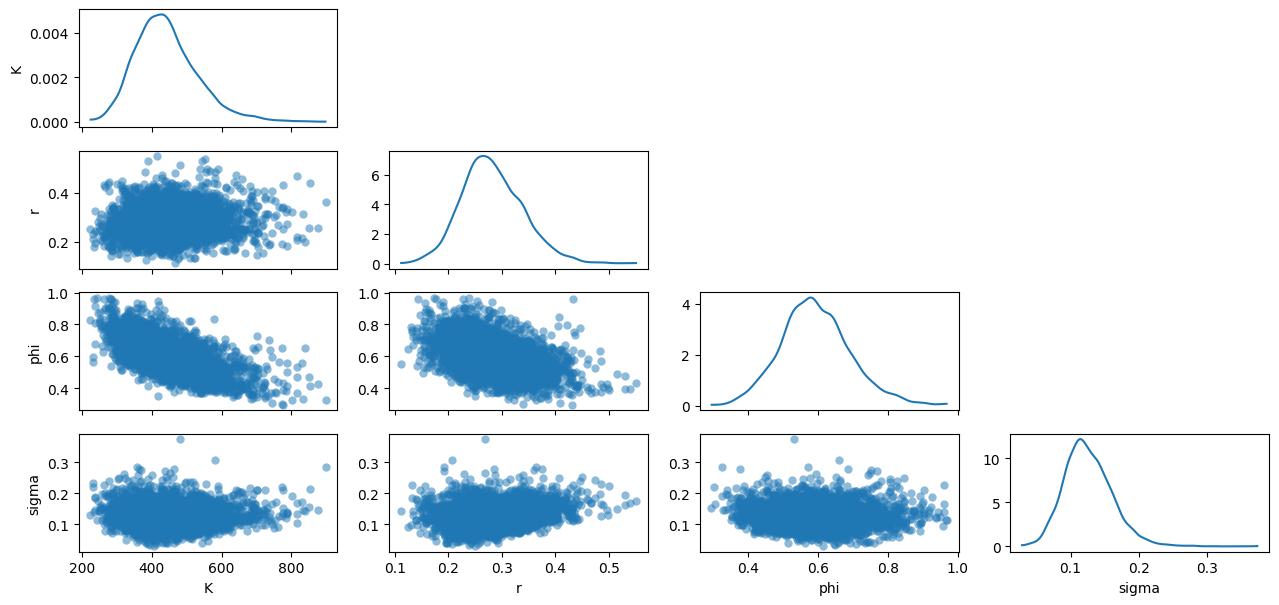

In [8]:
# summary of the posterior distribution, excluding e
params = ['K', 'r', 'phi', 'sigma']
summary = summarize(posterior[params])
print(summary)

# visual summary of the posterior distribution, excluding e
az.plot_pair(posterior.annotations['arviz'], var_names=params)
plt.show()

## 3. Predictive checks on the new model

Let's run the same predictive check from the previous tutorial to see if things have improved.

In [9]:
# the statistic to test
def change_spread(y: jax.Array) -> jax.Array:
    return jnp.std(jnp.diff(y))

# run the checks
prior_check = predictive_check(likelihood, prior, change_spread, observed_counts)
posterior_check = predictive_check(likelihood, posterior, change_spread, observed_counts)

# inspect p-values
print('prior check p-value:', prior_check['p_value'])
print('posterior check p-value:', posterior_check['p_value'])

prior check p-value: 0.392
posterior check p-value: 0.388


The p-values look more reasonable this time around.

## Summary

This tutorial provided a small taste of the iterative model building process.
The core ProbPipe features used here had already been introduced in the preceding tutorials, 
but this notebook showed how they could be used in constructing a more complicated model.

A key takeaway is that very little of the code actually had to change. We only had to update
the parts of the model that we modified. Everything else (performing inference, predictive checks, etc.)
remained exactly the same.
 
In [Tutorial 4](04_forecasting.ipynb), we introduce some new ProbPipe features in 
utilizing the model developed here to forecast future moose populations.